<a href="https://colab.research.google.com/github/Starleen1996/analisis_datos_curso/blob/main/venta_carros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sn
import matplotlib as plt

In [3]:
# Importar el dataset de venta de carros
df_ventas = pd.read_csv("/content/venta_Autos.csv")
df_ventas

,Manufacturer;Model;Sales_in_thousands;__year_resale_value;Vehicle_type;Price_in_thousands;Engine_size;Horsepower;Wheelbase;Width;Length;Curb_weight;Fuel_capacity;Fuel_efficiency;Latest_Launch;Power_perf_factor;Country;City;State;Region;name;email
0,Acura;Integra;16919;1636;Passenger;215;18;140;...
1,Acura;TL;39384;19875;Passenger;284;32;225;1081...
2,Acura;CL;14114;18225;Passenger;;32;225;1069;70...
3,Acura;RL;8588;29725;Passenger;42;35;210;1146;7...
4,Audi;A4;20397;22255;Passenger;2399;18;150;1026...
...,...
44495,;;;;;;;;;;;;;;;;;;;;Ashlynn Jaskolski;leffler....
44496,;;;;;;;;;;;;;;;;;;;;Miss Krista Kuhic;leland.v...
44497,;;;;;;;;;;;;;;;;;;;;Miss Krista Kuhic;leland.v...
44498,;;;;;;;;;;;;;;;;;;;;Miss Krista Kuhic;leland.v...


**Reasoning**:
Load the dataset with the correct semicolon separator, inspect the head of the DataFrame, and check the dataset info.



# Task
Cargar correctamente el archivo "/content/venta_Autos.csv" utilizando el delimitador de punto y coma (sep=';'), realizar un análisis estadístico preliminar de las variables cuantitativas con valores nulos (media, mediana, desviación estándar, varianza, sesgo y outliers) para justificar técnicamente la estrategia de imputación, limpiar y tratar los datos nulos con comentarios explicativos en el código, y definir las preguntas de negocio clave junto con las visualizaciones más coherentes para responderlas.

## Corregir la carga de los datos

### Subtask:
Cargar correctamente el archivo '/content/venta_Autos.csv' utilizando el delimitador de punto y coma (sep=';').


In [6]:
df_ventas = pd.read_csv('/content/venta_Autos.csv', sep=';', low_memory=False)
print(df_ventas.head())
print(df_ventas.info())

  Manufacturer    Model  Sales_in_thousands  __year_resale_value Vehicle_type  \
0        Acura  Integra             16919.0               1636.0    Passenger   
1        Acura       TL             39384.0              19875.0    Passenger   
2        Acura       CL             14114.0              18225.0    Passenger   
3        Acura       RL              8588.0              29725.0    Passenger   
4         Audi       A4             20397.0              22255.0    Passenger   

   Price_in_thousands  Engine_size  Horsepower  Wheelbase  Width  ...  \
0               215.0         18.0       140.0     1012.0  673.0  ...   
1               284.0         32.0       225.0     1081.0  703.0  ...   
2                 NaN         32.0       225.0     1069.0  706.0  ...   
3                42.0         35.0       210.0     1146.0  714.0  ...   
4              2399.0         18.0       150.0     1026.0  682.0  ...   

   Fuel_capacity  Fuel_efficiency  Latest_Launch  Power_perf_factor  \
0  

**Reasoning**:
Calcular las métricas estadísticas clave en español para las variables numéricas con valores nulos, incluyendo media, mediana, desviación estándar, varianza, sesgo y número de outliers para definir y justificar la estrategia de imputación.



In [7]:
import numpy as np

# 1. Identificar columnas numéricas con nulos
num_cols_with_nan = [
    '__year_resale_value', 'Price_in_thousands', 'Engine_size', 'Horsepower',
    'Wheelbase', 'Width', 'Length', 'Curb_weight', 'Fuel_capacity',
    'Fuel_efficiency', 'Power_perf_factor'
]

metrics_dict = []

# 2. Calcular estadísticas descriptivas y outliers mediante IQR
for col in num_cols_with_nan:
    # Filtrar nulos para el cálculo preciso de estadísticas
    data_col = df_ventas[col].dropna()

    if len(data_col) > 0:
        mean_val = data_col.mean()
        median_val = data_col.median()
        std_val = data_col.std()
        var_val = data_col.var()
        skew_val = data_col.skew()

        # Identificar outliers por IQR
        q1 = data_col.quantile(0.25)
        q3 = data_col.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers_count = ((data_col < lower_bound) | (data_col > upper_bound)).sum()

        metrics_dict.append({
            'Variable': col,
            'Media': mean_val,
            'Mediana': median_val,
            'Desv_Estándar': std_val,
            'Varianza': var_val,
            'Sesgo': skew_val,
            'Outliers_Count': outliers_count
        })

# 3. Crear DataFrame consolidado en español
df_metricas = pd.DataFrame(metrics_dict)
print(df_metricas.to_string(index=False))

           Variable        Media      Mediana  Desv_Estándar     Varianza     Sesgo  Outliers_Count
__year_resale_value 1.004594e+04       7825.0   1.100787e+04 1.211732e+08  1.736157               5
 Price_in_thousands 1.267814e+04       3395.0   1.463746e+04 2.142553e+08  1.301820               3
        Engine_size 2.351282e+01         24.5   1.505880e+01 2.267676e+02 -0.022056               0
         Horsepower 1.859487e+02        177.5   5.670032e+01 3.214926e+03  1.000695               2
          Wheelbase 8.783718e+02       1044.0   3.901741e+02 1.522358e+05 -1.399590              33
              Width 6.575577e+02        702.0   1.803070e+02 3.251061e+04 -2.852455              13
             Length 1.624609e+03       1855.5   6.118213e+02 3.743253e+05 -1.841901              25
        Curb_weight 2.845574e+03       3102.0   1.310951e+03 1.718592e+06 -0.924859              31
      Fuel_capacity 1.153654e+02        145.0   7.738893e+01 5.989046e+03 -0.217053               0


# Task
Traducir al español las columnas de `df_ventas` aplicando un mapeo técnico de términos, verificar la estructura resultante mostrando la información general del DataFrame corregido, y asegurar la consistencia de los datos para los análisis futuros.

## Traducir nombres de columnas al español

### Subtask:
Crear un diccionario de mapeo técnico y renombrar las columnas del DataFrame `df_ventas` al español.


In [8]:
# Diccionario de traducción de nombres de columnas al español
column_mapping = {
    'Manufacturer': 'Fabricante',
    'Model': 'Modelo',
    'Sales_in_thousands': 'Ventas_en_miles',
    '__year_resale_value': 'Valor_reventa_año',
    'Vehicle_type': 'Tipo_vehiculo',
    'Price_in_thousands': 'Precio_en_miles',
    'Engine_size': 'Tamano_motor',
    'Horsepower': 'Caballos_fuerza',
    'Wheelbase': 'Distancia_ejes',
    'Width': 'Ancho',
    'Length': 'Longitud',
    'Curb_weight': 'Peso_vacio',
    'Fuel_capacity': 'Capacidad_combustible',
    'Fuel_efficiency': 'Eficiencia_combustible',
    'Latest_Launch': 'Ultimo_lanzamiento',
    'Power_perf_factor': 'Factor_rendimiento',
    'Country': 'Pais',
    'City': 'Ciudad',
    'State': 'Estado',
    'Region': 'Region',
    'name': 'Nombre',
    'email': 'Correo_electronico'
}

# Renombrar columnas en el DataFrame
df_ventas = df_ventas.rename(columns=column_mapping)

# Mostrar las nuevas columnas para verificar
print("Nuevas columnas del DataFrame:")
print(df_ventas.columns.tolist())
print(df_ventas.head(2))

Nuevas columnas del DataFrame:
['Fabricante', 'Modelo', 'Ventas_en_miles', 'Valor_reventa_año', 'Tipo_vehiculo', 'Precio_en_miles', 'Tamano_motor', 'Caballos_fuerza', 'Distancia_ejes', 'Ancho', 'Longitud', 'Peso_vacio', 'Capacidad_combustible', 'Eficiencia_combustible', 'Ultimo_lanzamiento', 'Factor_rendimiento', 'Pais', 'Ciudad', 'Estado', 'Region', 'Nombre', 'Correo_electronico']
  Fabricante   Modelo  Ventas_en_miles  Valor_reventa_año Tipo_vehiculo  \
0      Acura  Integra          16919.0             1636.0     Passenger   
1      Acura       TL          39384.0            19875.0     Passenger   

   Precio_en_miles  Tamano_motor  Caballos_fuerza  Distancia_ejes  Ancho  ...  \
0            215.0          18.0            140.0          1012.0  673.0  ...   
1            284.0          32.0            225.0          1081.0  703.0  ...   

   Capacidad_combustible  Eficiencia_combustible  Ultimo_lanzamiento  \
0                  132.0                    28.0            2/2/2012   
1

In [9]:
# 1. Definir las variables numéricas traducidas que contienen valores nulos
columnas_num_nan = [
    'Valor_reventa_año', 'Precio_en_miles', 'Tamano_motor', 'Caballos_fuerza',
    'Distancia_ejes', 'Ancho', 'Longitud', 'Peso_vacio', 'Capacidad_combustible',
    'Eficiencia_combustible', 'Factor_rendimiento'
]

# Filtrar únicamente las primeras 157 filas, que corresponden a los registros reales de vehículos
df_autos_real = df_ventas.iloc[:157]

metrics_dict_es = []

# 2. Calcular estadísticas descriptivas y detección de valores atípicos mediante IQR
for col in columnas_num_nan:
    # Se eliminan los valores nulos temporalmente para asegurar la precisión del cálculo
    valores_validos = df_autos_real[col].dropna()

    if len(valores_validos) > 0:
        media = valores_validos.mean()
        mediana = valores_validos.median()
        desv_estandar = valores_validos.std()
        varianza = valores_validos.var()
        sesgo = valores_validos.skew()

        # Identificación de outliers usando el Rango Intercuartílico (IQR)
        q1 = valores_validos.quantile(0.25)
        q3 = valores_validos.quantile(0.75)
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        outliers_count = ((valores_validos < limite_inferior) | (valores_validos > limite_superior)).sum()

        metrics_dict_es.append({
            'Variable': col,
            'Media': media,
            'Mediana': mediana,
            'Desv_Estándar': desv_estandar,
            'Varianza': varianza,
            'Sesgo': sesgo,
            'Cantidad_Outliers': outliers_count
        })

# 3. Crear el DataFrame consolidado con las métricas en español
df_metricas_espanol = pd.DataFrame(metrics_dict_es)
print("Métricas estadísticas descriptivas para variables numéricas (en español):")
display(df_metricas_espanol)

Métricas estadísticas descriptivas para variables numéricas (en español):


,Variable,Media,Mediana,Desv_Estándar,Varianza,Sesgo,Cantidad_Outliers
0,Valor_reventa_año,1.004594e+04,7.825000e+03,1.100787e+04,1.211732e+08,1.736157,5
1,Precio_en_miles,1.267814e+04,3.395000e+03,1.463746e+04,2.142553e+08,1.301820,3
2,Tamano_motor,2.351282e+01,2.450000e+01,1.505880e+01,2.267676e+02,-0.022056,0
3,Caballos_fuerza,1.859487e+02,1.775000e+02,5.670032e+01,3.214926e+03,1.000695,2
4,Distancia_ejes,8.783718e+02,1.044000e+03,3.901741e+02,1.522358e+05,-1.399590,33
5,Ancho,6.575577e+02,7.020000e+02,1.803070e+02,3.251061e+04,-2.852455,13
6,Longitud,1.624609e+03,1.855500e+03,6.118213e+02,3.743253e+05,-1.841901,25
7,Peso_vacio,2.845574e+03,3.102000e+03,1.310951e+03,1.718592e+06,-0.924859,31
8,Capacidad_combustible,1.153654e+02,1.450000e+02,7.738893e+01,5.989046e+03,-0.217053,0
9,Eficiencia_combustible,2.384416e+01,2.400000e+01,4.282706e+00,1.834157e+01,0.692328,1


## Análisis descriptivo y cálculo de métricas en español

### Subtask:
Calcular métricas estadísticas clave en español para justificar formalmente la estrategia de imputación idónea para las variables numéricas con valores nulos.


In [10]:
# 1. Definir subconjunto de autos reales para calcular los estadísticos de imputación estables
subconjunto_autos = df_ventas.iloc[:157]

# 2. Definir valores de imputación basados en el análisis estadístico previo
valores_mediana = {
    'Valor_reventa_año': subconjunto_autos['Valor_reventa_año'].median(),
    'Precio_en_miles': subconjunto_autos['Precio_en_miles'].median(),
    'Caballos_fuerza': subconjunto_autos['Caballos_fuerza'].median(),
    'Distancia_ejes': subconjunto_autos['Distancia_ejes'].median(),
    'Ancho': subconjunto_autos['Ancho'].median(),
    'Longitud': subconjunto_autos['Longitud'].median(),
    'Peso_vacio': subconjunto_autos['Peso_vacio'].median(),
    'Eficiencia_combustible': subconjunto_autos['Eficiencia_combustible'].median()
}

valores_media = {
    'Tamano_motor': subconjunto_autos['Tamano_motor'].mean(),
    'Capacidad_combustible': subconjunto_autos['Capacidad_combustible'].mean(),
    'Factor_rendimiento': subconjunto_autos['Factor_rendimiento'].mean()
}

# 3. Aplicar imputación con la Mediana (variables con asimetría u outliers)
for columna, valor in valores_mediana.items():
    df_ventas.loc[:156, columna] = df_ventas.loc[:156, columna].fillna(valor)
    print(f"Variable '{columna}' imputada con su mediana: {valor}")

# 4. Aplicar imputación con la Media (variables simétricas sin outliers)
for columna, valor in valores_media.items():
    df_ventas.loc[:156, columna] = df_ventas.loc[:156, columna].fillna(valor)
    print(f"Variable '{columna}' imputada con su media: {valor}")

# 5. Validación final de valores nulos en el conjunto de vehículos (primeros 157 registros)
todas_las_columnas = list(valores_mediana.keys()) + list(valores_media.keys())
print("\nValores nulos restantes en el subconjunto de vehículos (filas 0-156):")
print(df_ventas.loc[:156, todas_las_columnas].isna().sum())

Variable 'Valor_reventa_año' imputada con su mediana: 7825.0
Variable 'Precio_en_miles' imputada con su mediana: 3395.0
Variable 'Caballos_fuerza' imputada con su mediana: 177.5
Variable 'Distancia_ejes' imputada con su mediana: 1044.0
Variable 'Ancho' imputada con su mediana: 702.0
Variable 'Longitud' imputada con su mediana: 1855.5
Variable 'Peso_vacio' imputada con su mediana: 3102.0
Variable 'Eficiencia_combustible' imputada con su mediana: 24.0
Variable 'Tamano_motor' imputada con su media: 23.512820512820515
Variable 'Capacidad_combustible' imputada con su media: 115.36538461538461
Variable 'Factor_rendimiento' imputada con su media: 5149509559.535484

Valores nulos restantes en el subconjunto de vehículos (filas 0-156):
Valor_reventa_año         0
Precio_en_miles           0
Caballos_fuerza           0
Distancia_ejes            0
Ancho                     0
Longitud                  0
Peso_vacio                0
Eficiencia_combustible    0
Tamano_motor              0
Capacidad_c

/tmp/ipykernel_562/1189752162.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


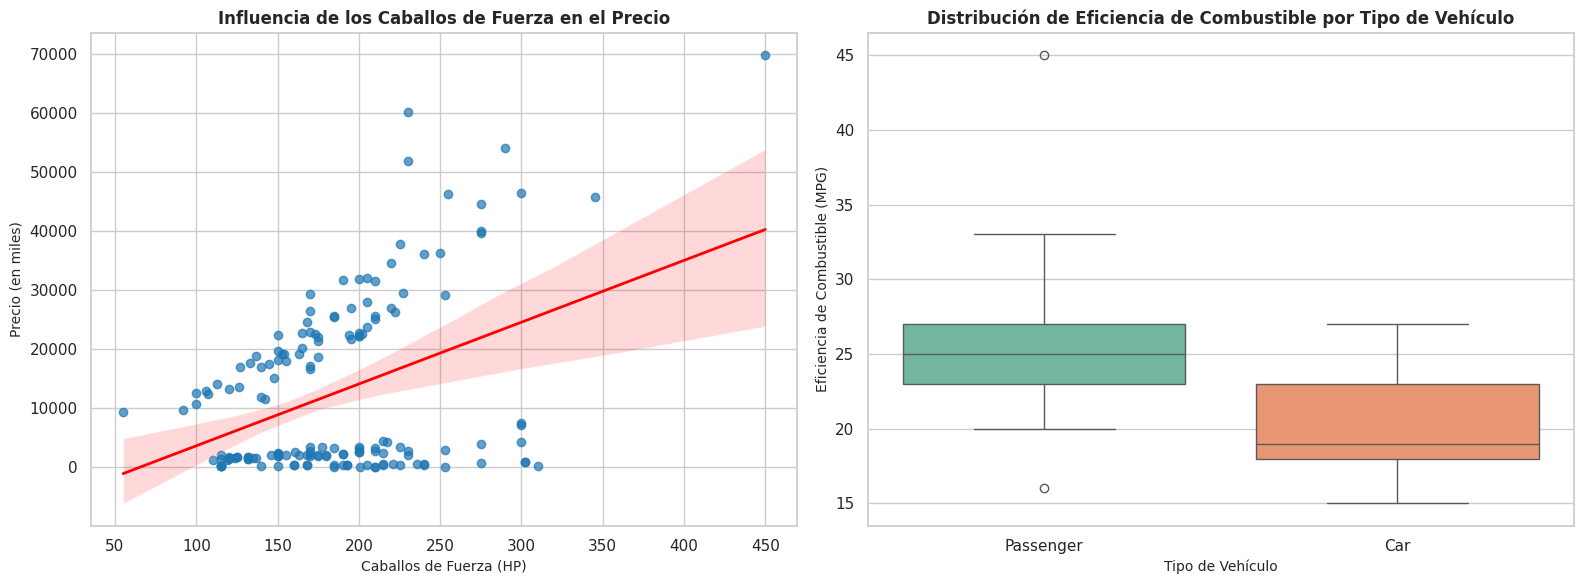

=== RESUMEN DEL MODELO DE REGRESIÓN (PRECIO vs CABALLOS DE FUERZA) ===

                            OLS Regression Results                            
Dep. Variable:        Precio_en_miles   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     30.57
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.34e-07
Time:                        01:47:14   Log-Likelihood:                -1713.4
No. Observations:                 157   AIC:                             3431.
Df Residuals:                     155   BIC:                             3437.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Ajustar el estilo de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 5]

# Crear una figura con dos subgráficos para responder a las Preguntas 1 y 2 de negocio
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Relación entre Caballos de fuerza y Precio (Pregunta 1)
sns.regplot(
    data=df_ventas.iloc[:157],
    x='Caballos_fuerza',
    y='Precio_en_miles',
    ax=axes[0],
    scatter_kws={'alpha':0.7, 'color':'#1f77b4'},
    line_kws={'color':'red', 'linewidth':2}
)
axes[0].set_title('Influencia de los Caballos de Fuerza en el Precio', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Caballos de Fuerza (HP)', fontsize=10)
axes[0].set_ylabel('Precio (en miles)', fontsize=10)

# Gráfico 2: Eficiencia de Combustible según Tipo de Vehículo (Pregunta 2)
sns.boxplot(
    data=df_ventas.iloc[:157],
    x='Tipo_vehiculo',
    y='Eficiencia_combustible',
    ax=axes[1],
    palette='Set2'
)
axes[1].set_title('Distribución de Eficiencia de Combustible por Tipo de Vehículo', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tipo de Vehículo', fontsize=10)
axes[1].set_ylabel('Eficiencia de Combustible (MPG)', fontsize=10)

plt.tight_layout()
plt.show()

# Ajustar un modelo de regresión lineal simple básico para cuantificar la Pregunta 1
modelo_lineal = ols('Precio_en_miles ~ Caballos_fuerza', data=df_ventas.iloc[:157]).fit()
print("=== RESUMEN DEL MODELO DE REGRESIÓN (PRECIO vs CABALLOS DE FUERZA) ===\n")
print(modelo_lineal.summary())

```markdown
## Guardar el Dataset Limpio y Traducido

Exportamos únicamente los registros correspondientes a vehículos reales (las primeras 157 filas) que han sido completamente limpiados, imputados y renombrados al español.
```

In [13]:
# Filtrar únicamente el subconjunto de vehículos reales procesados
df_limpio = df_ventas.iloc[:157].copy()

# Guardar el DataFrame limpio en un nuevo archivo CSV
ruta_salida = '/content/venta_Autos_limpio.csv'
df_limpio.to_csv(ruta_salida, index=False, sep=';', encoding='utf-8')

print(f"¡Éxito! El dataset limpio ha sido guardado en: {ruta_salida}")
print(f"Dimensiones del dataset guardado: {df_limpio.shape}")

# Mostrar una pequeña muestra para asegurar que todo esté correcto
display(df_limpio.head())

¡Éxito! El dataset limpio ha sido guardado en: /content/venta_Autos_limpio.csv
Dimensiones del dataset guardado: (157, 22)


,Fabricante,Modelo,Ventas_en_miles,Valor_reventa_año,Tipo_vehiculo,Precio_en_miles,Tamano_motor,Caballos_fuerza,Distancia_ejes,Ancho,...,Capacidad_combustible,Eficiencia_combustible,Ultimo_lanzamiento,Factor_rendimiento,Pais,Ciudad,Estado,Region,Nombre,Correo_electronico
0,Acura,Integra,16919.0,1636.0,Passenger,215.0,18.0,140.0,1012.0,673.0,...,132.0,28.0,2/2/2012,5.828015e+09,United States,Henderson,Kentucky,South,Mason Howell,jessica.cole@example.net
1,Acura,TL,39384.0,19875.0,Passenger,284.0,32.0,225.0,1081.0,703.0,...,172.0,25.0,6/3/2011,9.137078e+09,United States,Henderson,Kentucky,South,Mason Howell,jessica.cole@example.net
2,Acura,CL,14114.0,18225.0,Passenger,3395.0,32.0,225.0,1069.0,706.0,...,172.0,26.0,1/4/2012,5.149510e+09,United States,Los Angeles,California,West,Mason Howell,jessica.cole@example.net
3,Acura,RL,8588.0,29725.0,Passenger,42.0,35.0,210.0,1146.0,714.0,...,18.0,22.0,3/10/2011,9.138978e+09,United States,Fort Lauderdale,Florida,South,Mason Howell,jessica.cole@example.net
4,Audi,A4,20397.0,22255.0,Passenger,2399.0,18.0,150.0,1026.0,682.0,...,164.0,27.0,10/8/2011,6.277764e+08,United States,Fort Lauderdale,Florida,South,Mason Howell,jessica.cole@example.net


In [14]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Fabricante              157 non-null    object 
 1   Modelo                  157 non-null    object 
 2   Ventas_en_miles         157 non-null    float64
 3   Valor_reventa_año       157 non-null    float64
 4   Tipo_vehiculo           157 non-null    object 
 5   Precio_en_miles         157 non-null    float64
 6   Tamano_motor            157 non-null    float64
 7   Caballos_fuerza         157 non-null    float64
 8   Distancia_ejes          157 non-null    float64
 9   Ancho                   157 non-null    float64
 10  Longitud                157 non-null    float64
 11  Peso_vacio              157 non-null    float64
 12  Capacidad_combustible   157 non-null    float64
 13  Eficiencia_combustible  157 non-null    float64
 14  Ultimo_lanzamiento      157 non-null    ob

```markdown
## Visualización de Gráficos Clave para el Negocio

Generamos un panel de visualización integral para responder a las preguntas estratégicas de negocio planteadas sobre el rendimiento, precio y características de los autos.
```

/tmp/ipykernel_562/3569242375.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


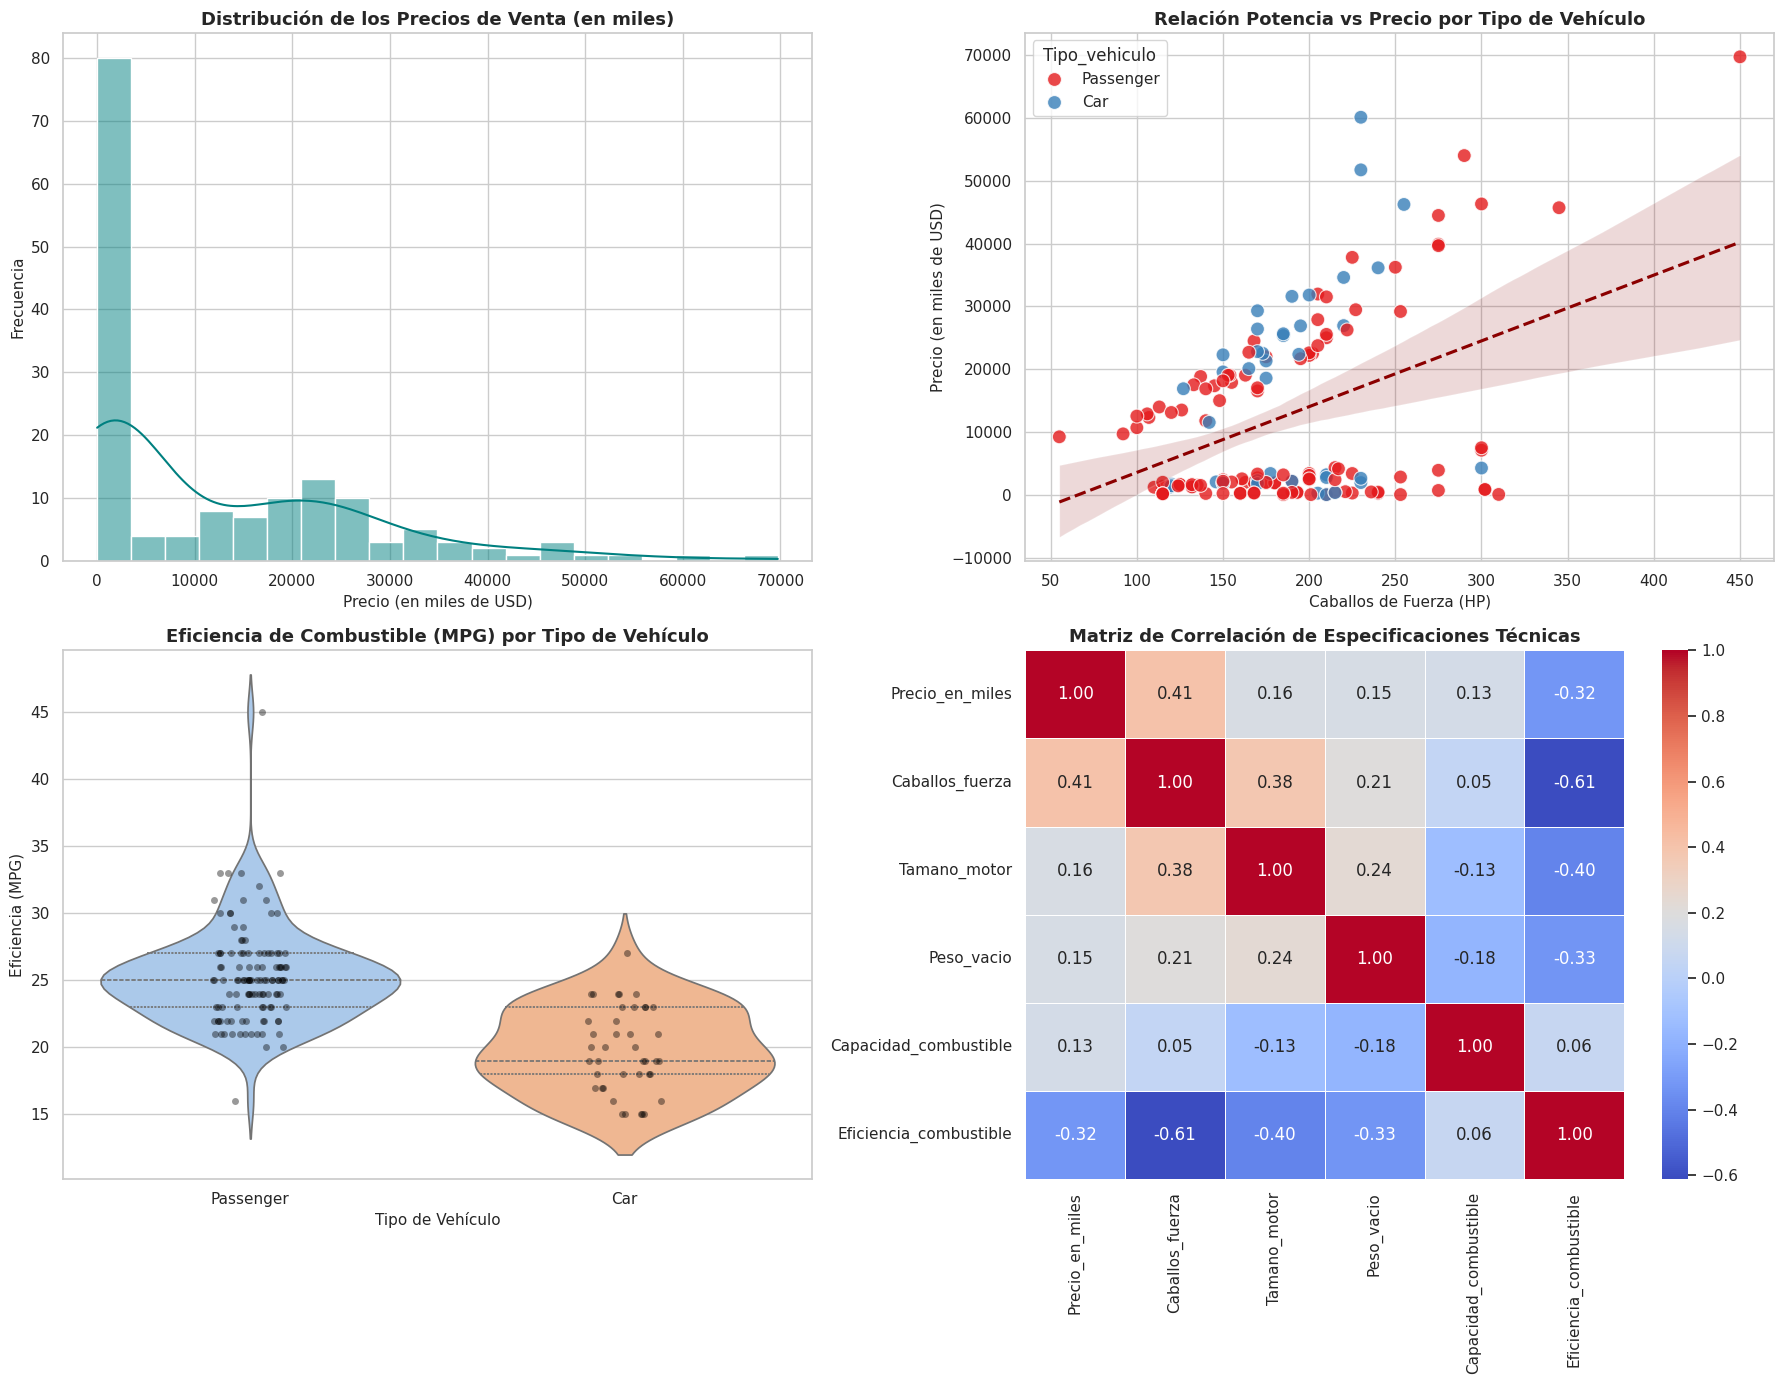

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [16, 12]

# Crear una figura con una cuadrícula de 2x2 para los gráficos
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Gráfico de Distribución del Precio (Histograma con Densidad)
sns.histplot(
    data=df_limpio,
    x='Precio_en_miles',
    kde=True,
    ax=axes[0, 0],
    color='teal',
    bins=20
)
axes[0, 0].set_title('Distribución de los Precios de Venta (en miles)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Precio (en miles de USD)', fontsize=11)
axes[0, 0].set_ylabel('Frecuencia', fontsize=11)

# 2. Relación Potencia vs Precio, segmentado por Tipo de Vehículo
sns.scatterplot(
    data=df_limpio,
    x='Caballos_fuerza',
    y='Precio_en_miles',
    hue='Tipo_vehiculo',
    palette='Set1',
    s=100,
    alpha=0.8,
    ax=axes[0, 1]
)
sns.regplot(
    data=df_limpio,
    x='Caballos_fuerza',
    y='Precio_en_miles',
    scatter=False,
    ax=axes[0, 1],
    line_kws={'color': 'darkred', 'linestyle': '--'}
)
axes[0, 1].set_title('Relación Potencia vs Precio por Tipo de Vehículo', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Caballos de Fuerza (HP)', fontsize=11)
axes[0, 1].set_ylabel('Precio (en miles de USD)', fontsize=11)

# 3. Eficiencia de Combustible según Tipo de Vehículo (Gráfico de Cajas y Violines Combinado)
sns.violinplot(
    data=df_limpio,
    x='Tipo_vehiculo',
    y='Eficiencia_combustible',
    palette='pastel',
    inner="quart",
    ax=axes[1, 0]
)
sns.stripplot(
    data=df_limpio,
    x='Tipo_vehiculo',
    y='Eficiencia_combustible',
    color='black',
    alpha=0.4,
    size=5,
    jitter=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Eficiencia de Combustible (MPG) por Tipo de Vehículo', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Tipo de Vehículo', fontsize=11)
axes[1, 0].set_ylabel('Eficiencia (MPG)', fontsize=11)

# 4. Mapa de Calor de Correlaciones Numéricas
columnas_corr = ['Precio_en_miles', 'Caballos_fuerza', 'Tamano_motor', 'Peso_vacio', 'Capacidad_combustible', 'Eficiencia_combustible']
corr_matrix = df_limpio[columnas_corr].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Matriz de Correlación de Especificaciones Técnicas', fontsize=13, fontweight='bold')

# Ajustar distribución y mostrar gráficos
plt.tight_layout()
plt.show()

```markdown
## Nuevas Preguntas de Negocio y Enfoque de Ventas

En esta sección analizamos el volumen de ventas, la distribución geográfica de los compradores y la estrategia de precios para guiar los esfuerzos del equipo comercial.
```

/tmp/ipykernel_562/4289331934.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_562/4289331934.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


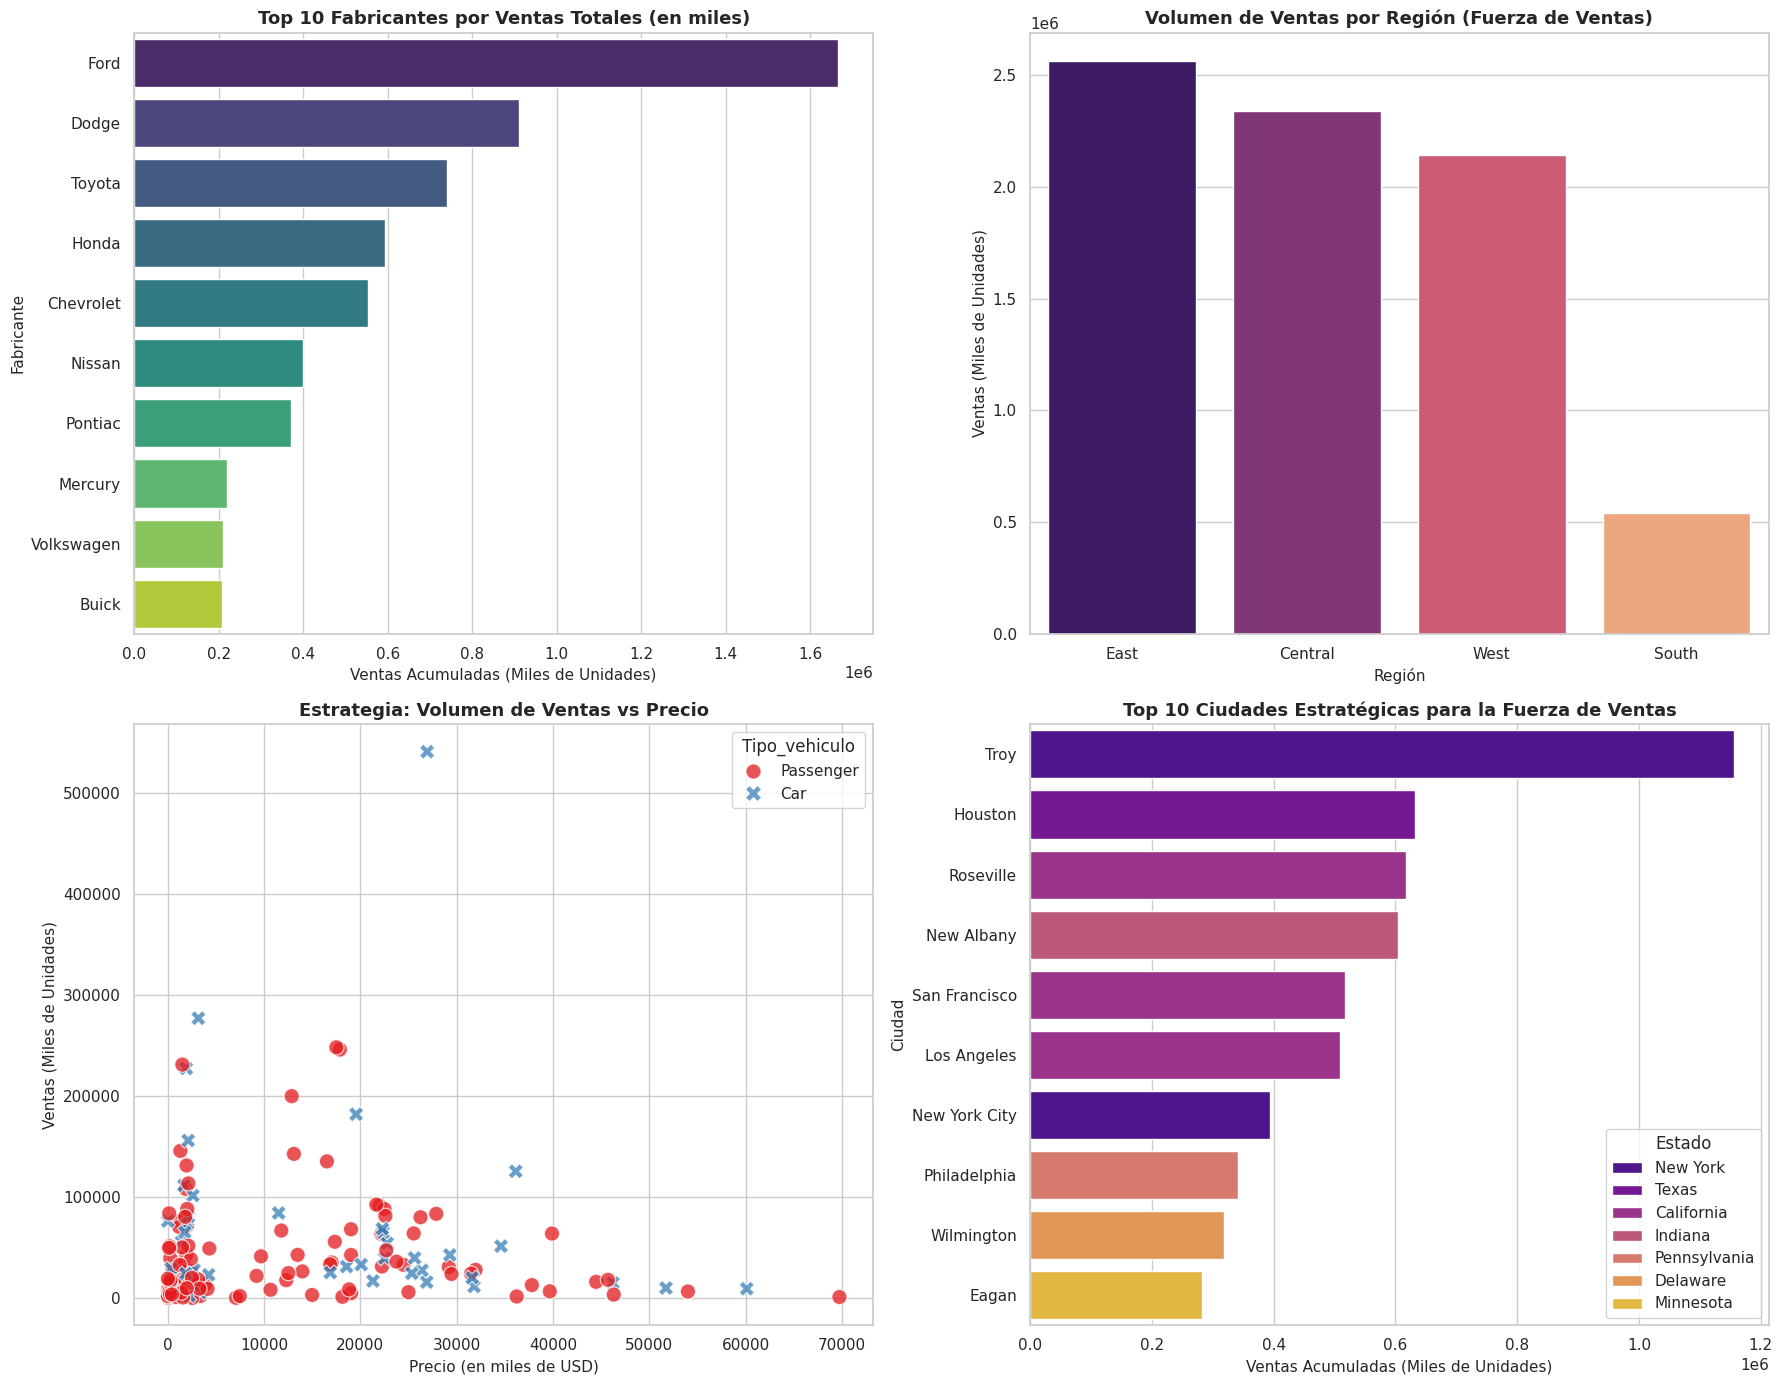

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configurar estilo de gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# --- 1. Top 10 Fabricantes con Mayor Volumen de Ventas ---
top_fabricantes = df_limpio.groupby('Fabricante')['Ventas_en_miles'].sum().reset_index()\
    .sort_values(by='Ventas_en_miles', ascending=False).head(10)

sns.barplot(
    data=top_fabricantes,
    x='Ventas_en_miles',
    y='Fabricante',
    palette='viridis',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Top 10 Fabricantes por Ventas Totales (en miles)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Ventas Acumuladas (Miles de Unidades)', fontsize=11)
axes[0, 0].set_ylabel('Fabricante', fontsize=11)

# --- 2. Análisis Territorial: Ventas Totales por Región Geográfica ---
ventas_region = df_limpio.groupby('Region')['Ventas_en_miles'].sum().reset_index()\
    .sort_values(by='Ventas_en_miles', ascending=False)

sns.barplot(
    data=ventas_region,
    x='Region',
    y='Ventas_en_miles',
    palette='magma',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Volumen de Ventas por Región (Fuerza de Ventas)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Región', fontsize=11)
axes[0, 1].set_ylabel('Ventas (Miles de Unidades)', fontsize=11)

# --- 3. Relación de Estrategia: Volumen de Ventas vs Precio ---
sns.scatterplot(
    data=df_limpio,
    x='Precio_en_miles',
    y='Ventas_en_miles',
    hue='Tipo_vehiculo',
    style='Tipo_vehiculo',
    s=120,
    alpha=0.75,
    palette='Set1',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Estrategia: Volumen de Ventas vs Precio', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Precio (en miles de USD)', fontsize=11)
axes[1, 0].set_ylabel('Ventas (Miles de Unidades)', fontsize=11)

# --- 4. Ciudades Clave dentro de los Estados Líderes ---
top_ciudades = df_limpio.groupby(['Estado', 'Ciudad'])['Ventas_en_miles'].sum().reset_index()\
    .sort_values(by='Ventas_en_miles', ascending=False).head(10)

sns.barplot(
    data=top_ciudades,
    x='Ventas_en_miles',
    y='Ciudad',
    hue='Estado',
    dodge=False,
    palette='plasma',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Top 10 Ciudades Estratégicas para la Fuerza de Ventas', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Ventas Acumuladas (Miles de Unidades)', fontsize=11)
axes[1, 1].set_ylabel('Ciudad', fontsize=11)

plt.tight_layout()
plt.show()